# 01 — Analyse exploratoire (EDA)

**Objectif :** caractériser les environnements et les agents *avant* de comparer les algorithmes.

Questions posées :
1. À quoi ressemblent les environnements générés (taille, densité d'obstacles, espace libre) ?
2. Quelles distances les agents doivent-ils parcourir, et combien les obstacles les rallongent-ils ?
3. Si chaque agent planifie seul (A* indépendant), combien de conflits apparaissent, où et quand ?

**Jeu de données :** 50 scénarios aléatoires (graines 0 à 49) pour chaque configuration : grilles 10×10 et 20×20, 15 % d'obstacles, 2 et 5 agents.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.environment import ScenarioGenerator
from src.coordinator import IndependentPlanner, detect_conflicts
from src.visualization import plot_paths

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 2)
FIG = "../results/"
SEEDS = range(50)
CONFIGS = [(10, 2), (10, 5), (20, 2), (20, 5)]   # (taille de grille, nombre d'agents)
OBSTACLE_RATIO = 0.15

## 1. Construction du jeu de données

Pour chaque scénario, on planifie chaque agent **seul** avec A* (baseline sans coordination) et on enregistre une ligne par agent et une ligne par conflit.

In [2]:
agent_rows, conflict_rows, scenario_rows = [], [], []
examples = {}

for size, n in CONFIGS:
    for seed in SEEDS:
        grid, agents = ScenarioGenerator(size, size, OBSTACLE_RATIO, seed=seed).generate(n)
        IndependentPlanner(grid).solve(agents)
        conflicts = detect_conflicts(agents)
        if seed == 3:
            examples[(size, n)] = (grid, agents)

        scenario_rows.append(dict(grid=f"{size}x{size}", n_agents=n, seed=seed,
                                  free_cells=len(grid.free_cells()),
                                  obstacle_density=grid.obstacle_density,
                                  n_conflicts=len(conflicts)))
        for a in agents:
            agent_rows.append(dict(grid=f"{size}x{size}", n_agents=n, seed=seed, agent=a.agent_id,
                                   manhattan=a.manhattan_distance, astar_length=a.travel_distance,
                                   detour=a.travel_distance - a.manhattan_distance))
        for c in conflicts:
            loc = c.location if c.kind == "vertex" else c.location[0]
            conflict_rows.append(dict(grid=f"{size}x{size}", n_agents=n, seed=seed,
                                      kind=c.kind, time=c.time, row=loc[0], col=loc[1]))

agents_df = pd.DataFrame(agent_rows)
conflicts_df = pd.DataFrame(conflict_rows)
scenarios_df = pd.DataFrame(scenario_rows)
agents_df.to_csv(FIG + "eda_agents.csv", index=False)
scenarios_df.to_csv(FIG + "eda_scenarios.csv", index=False)
print(len(scenarios_df), "scénarios,", len(agents_df), "agents,", len(conflicts_df), "conflits")

200 scénarios, 700 agents, 111 conflits


## 2. Statistiques descriptives

### 2.1 Environnement

In [3]:
scenarios_df.groupby("grid")[["free_cells", "obstacle_density"]].describe().T

grid                     10x10   20x20
free_cells       count  100.00  100.00
                 mean    85.00  340.00
                 std      0.00    0.00
                 min     85.00  340.00
                 25%     85.00  340.00
                 50%     85.00  340.00
                 75%     85.00  340.00
                 max     85.00  340.00
obstacle_density count  100.00  100.00
                 mean     0.15    0.15
                 std      0.00    0.00
                 min      0.15    0.15
                 25%      0.15    0.15
                 50%      0.15    0.15
                 75%      0.15    0.15
                 max      0.15    0.15

### 2.2 Trajectoires des agents

`manhattan` est une borne inférieure (pas d'obstacles) ; `detour` = longueur A* − Manhattan mesure l'effet des obstacles.

In [4]:
agents_df.groupby("grid")[["manhattan", "astar_length", "detour"]].describe().T

grid                 10x10   20x20
manhattan    count  350.00  350.00
             mean     6.57   13.47
             std      3.12    6.46
             min      1.00    1.00
             25%      4.00    8.25
             50%      6.00   13.00
             75%      9.00   18.00
             max     16.00   32.00
astar_length count  350.00  350.00
             mean     7.00   14.11
             std      3.36    6.49
             min      1.00    1.00
             25%      5.00    9.00
             50%      7.00   14.00
             75%      9.00   18.75
             max     17.00   32.00
detour       count  350.00  350.00
             mean     0.42    0.65
             std      1.20    1.51
             min      0.00    0.00
             25%      0.00    0.00
             50%      0.00    0.00
             75%      0.00    0.00
             max      8.00   16.00

In [5]:
print("Part des agents sans aucun détour :",
      f"{100 * (agents_df.detour == 0).mean():.1f} %")

Part des agents sans aucun détour : 81.0 %


## 3. Visualisation d'un scénario

Départ = cercle, cible = étoile, obstacle = case noire, conflit = X rouge.

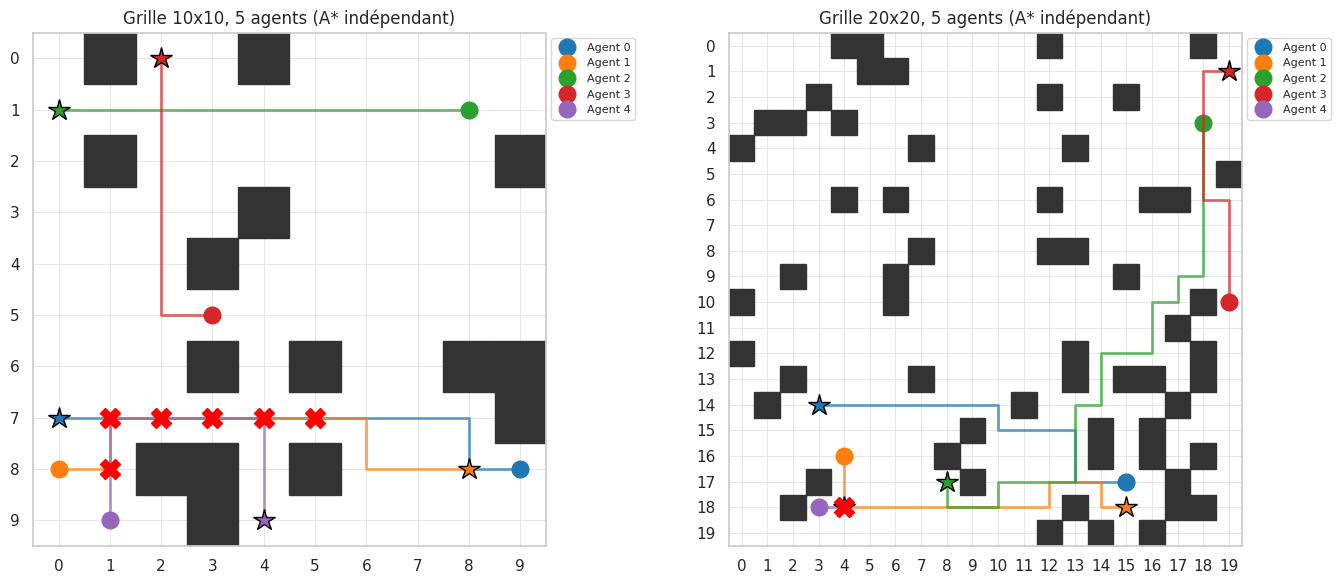

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, key in zip(axes, [(10, 5), (20, 5)]):
    grid, agents = examples[key]
    plot_paths(grid, agents, ax, title=f"Grille {key[0]}x{key[0]}, {key[1]} agents (A* indépendant)")
plt.tight_layout(); plt.savefig(FIG + "eda_example_scenarios.png", dpi=120); plt.show()

## 4. Analyse des distances

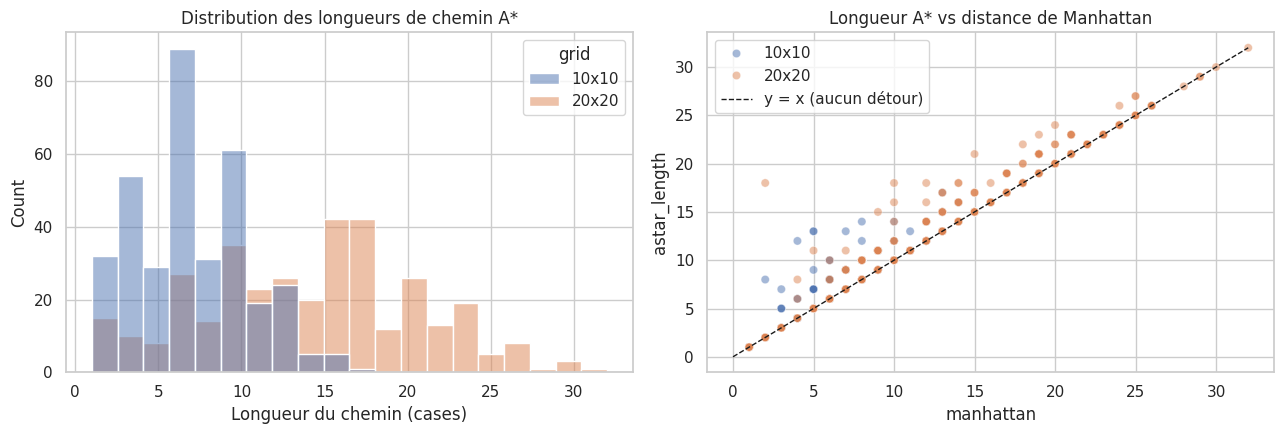

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=agents_df, x="astar_length", hue="grid", bins=20, ax=axes[0])
axes[0].set_title("Distribution des longueurs de chemin A*")
axes[0].set_xlabel("Longueur du chemin (cases)")

sns.scatterplot(data=agents_df, x="manhattan", y="astar_length", hue="grid", alpha=0.5, ax=axes[1])
lim = agents_df.astar_length.max()
axes[1].plot([0, lim], [0, lim], "k--", linewidth=1, label="y = x (aucun détour)")
axes[1].set_title("Longueur A* vs distance de Manhattan")
axes[1].legend()
plt.tight_layout(); plt.savefig(FIG + "eda_distances.png", dpi=120); plt.show()

Lecture : tous les points sont **au-dessus ou sur** la diagonale, ce qui confirme que Manhattan est une borne inférieure (heuristique admissible). L'écart à la diagonale correspond aux détours imposés par les obstacles.

## 5. Analyse des conflits potentiels (sans coordination)

In [8]:
summary = scenarios_df.groupby(["grid", "n_agents"]).agg(
    conflits_moyens=("n_conflicts", "mean"),
    conflits_max=("n_conflicts", "max"),
    scenarios_avec_conflit_pct=("n_conflicts", lambda s: 100 * (s > 0).mean()),
)
summary

conflits_moyens  conflits_max  scenarios_avec_conflit_pct
grid  n_agents                                                           
10x10 2                    0.10             2                         8.0
      5                    1.38             6                        72.0
20x20 2                    0.06             1                         6.0
      5                    0.68             3                        52.0

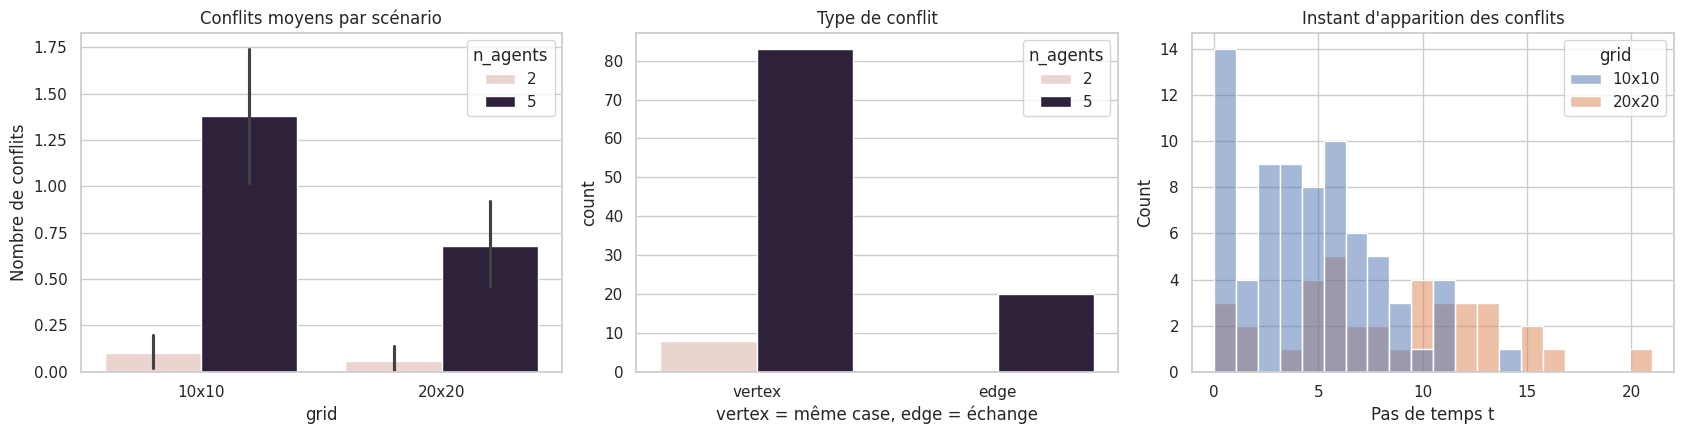

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.barplot(data=scenarios_df, x="grid", y="n_conflicts", hue="n_agents", ax=axes[0])
axes[0].set_title("Conflits moyens par scénario")
axes[0].set_ylabel("Nombre de conflits")

sns.countplot(data=conflicts_df, x="kind", hue="n_agents", ax=axes[1])
axes[1].set_title("Type de conflit")
axes[1].set_xlabel("vertex = même case, edge = échange")

sns.histplot(data=conflicts_df, x="time", hue="grid", bins=20, ax=axes[2])
axes[2].set_title("Instant d'apparition des conflits")
axes[2].set_xlabel("Pas de temps t")
plt.tight_layout(); plt.savefig(FIG + "eda_conflicts.png", dpi=120); plt.show()

### Où les conflits se produisent-ils ?

Carte de chaleur des positions de conflit sur les 50 scénarios 10×10 à 5 agents.

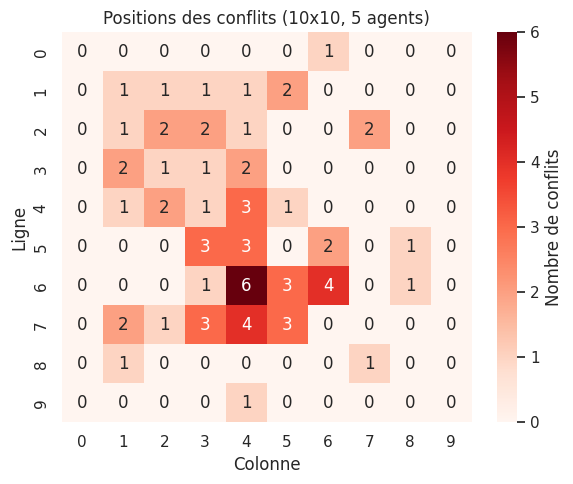

In [10]:
sub = conflicts_df[(conflicts_df.grid == "10x10") & (conflicts_df.n_agents == 5)]
heat = np.zeros((10, 10))
for r, c in zip(sub.row, sub.col):
    heat[r, c] += 1
plt.figure(figsize=(6, 5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "Nombre de conflits"})
plt.title("Positions des conflits (10x10, 5 agents)")
plt.xlabel("Colonne"); plt.ylabel("Ligne")
plt.tight_layout(); plt.savefig(FIG + "eda_conflict_heatmap.png", dpi=120); plt.show()

## 6. Conclusions de l'EDA

À compléter avec tes propres mots après exécution, en t'appuyant sur les chiffres ci-dessus :

- **Environnement :** densité d'obstacles constante (15 %) ; la 20×20 offre 4× plus d'espace libre.
- **Distances :** la plupart des chemins A* sont égaux ou proches de la distance de Manhattan ; les détours viennent des obstacles.
- **Conflits :** sans coordination, les conflits augmentent nettement avec le nombre d'agents et sont plus fréquents dans la petite grille (densité d'agents plus élevée). Ils apparaissent surtout en début de mission et dans les zones de passage centrales.
- **Conséquence :** un mécanisme de coordination est indispensable dès 5 agents → c'est l'objet du notebook `02_experiments`.